# 02 — Analyse des données logistics

**Groupe 3 — Siyaman MOHAMAD ; autres membres à compléter.**

**Question directrice :** les données décrivent-elles des flux cohérents, et où se trouvent
les particularités ou écarts récurrents à expliquer ? Le récit recherché est fictif.

Exécuter d’abord `01_nettoyage_logistics.ipynb`. Ce notebook charge ses sorties et fonctionne
dans un noyau indépendant : il ne dépend pas des variables d’un autre notebook.

In [1]:
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

dossier = Path("data/logistics_nettoyees")
if not dossier.exists():
    raise FileNotFoundError("Exécuter d’abord 01_nettoyage_logistics.ipynb")

tables_nettoyees = {
    fichier.stem: pd.read_pickle(fichier)
    for fichier in sorted(dossier.glob("*.pkl"))
}

display(pd.DataFrame({
    "nombre_lignes": {nom: len(df) for nom, df in tables_nettoyees.items()}
}))

,nombre_lignes
erp_business_partners,80
erp_facilities,30
goods_receipts,610
inventory_adjustments,140
inventory_month_end,500
purchase_order_lines,650
shipments,450


## 1. `shipments.csv` — Expéditions

### CM1 — Quantités par catégorie et unité
**Question :** quelles quantités sont habituelles et quelles valeurs méritent un examen ?
On sépare les catégories et unités pour comparer des quantités de même nature.
`describe()` donne l’effectif, la moyenne, l’écart-type, les quartiles et les extrêmes.
La médiane correspond à `50%`. Les services dont la quantité vaut toujours 1 sont peu
discriminants sur cette variable.

In [2]:
expeditions = tables_nettoyees["shipments"]

bilan_quantites = expeditions.groupby(
    ["item_category", "declared_unit"]
)["declared_quantity"].describe()

display(bilan_quantites.round(2))

,,count,mean,std,min,25%,50%,75%,max
item_category,declared_unit,,,,,,,,
agricultural_equipment,unit,19.0,11.00,6.62,2.0,5.50,10.0,16.50,21.0
agricultural_product,pallet,44.0,26.25,14.83,1.0,15.00,25.5,37.00,50.0
biological_sample,sealed_lot,52.0,6.54,4.38,1.0,3.00,6.0,8.00,18.0
cold_storage_equipment,unit,34.0,13.15,7.29,2.0,6.25,14.5,17.75,24.0
communication_service,service,15.0,1.00,0.00,1.0,1.00,1.0,1.00,1.0
consulting_service,service,21.0,1.00,0.00,1.0,1.00,1.0,1.00,1.0
grant,grant,7.0,1.00,0.00,1.0,1.00,1.0,1.00,1.0
laboratory_material,pack,31.0,34.94,17.08,3.0,26.00,36.0,49.00,60.0
legal_service,service,10.0,1.00,0.00,1.0,1.00,1.0,1.00,1.0


Les boîtes à moustaches complètent les chiffres en visualisant la dispersion.
Les catégories à quantité constante sont omises du graphique.

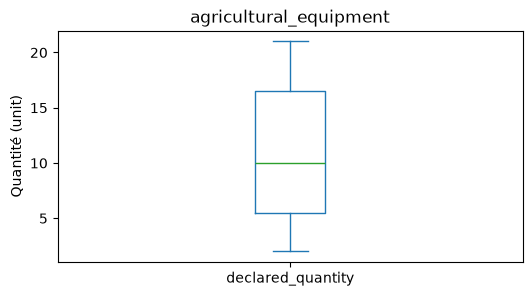

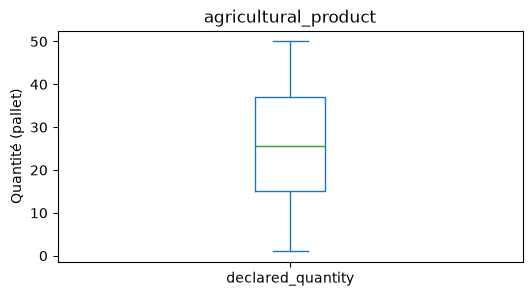

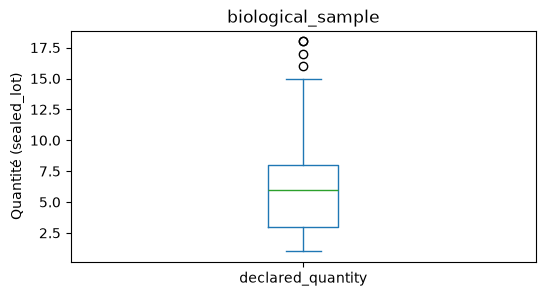

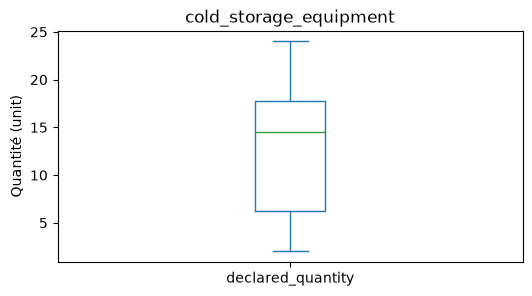

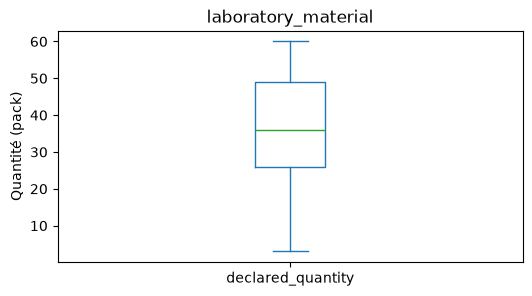

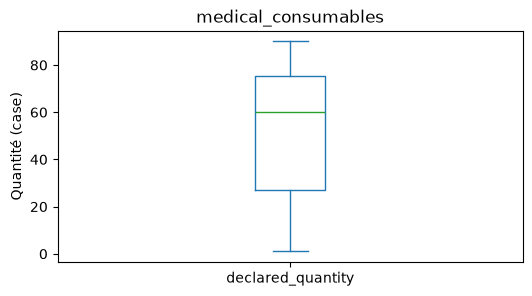

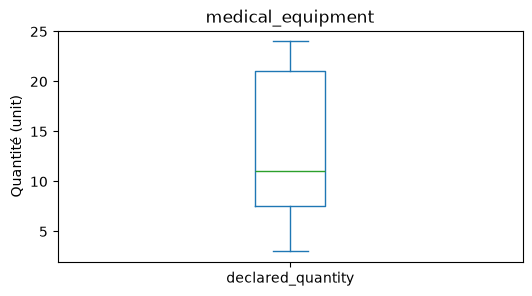

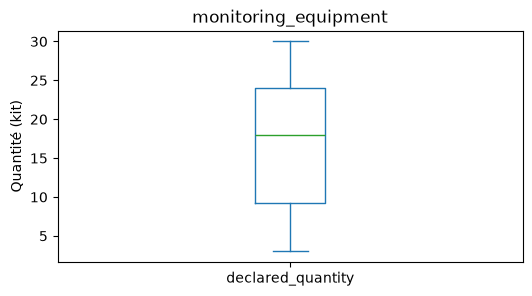

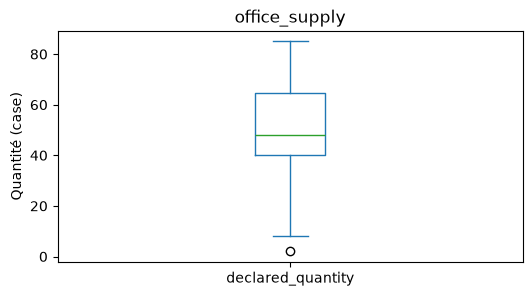

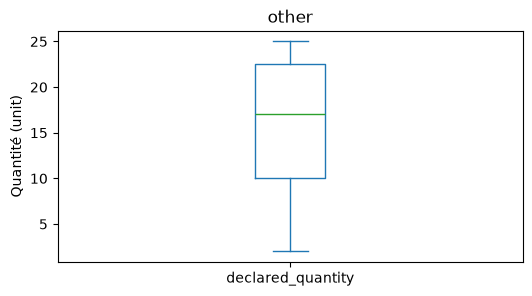

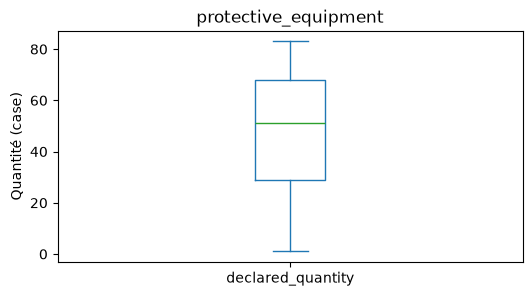

In [3]:
for (categorie, unite), groupe in expeditions.groupby(
    ["item_category", "declared_unit"]
):
    if groupe["declared_quantity"].nunique() <= 1:
        continue  # Ignorer les catégories où toutes les quantités sont identiques.

    groupe["declared_quantity"].plot.box(figsize=(6, 3))
    plt.title(categorie)
    plt.ylabel(f"Quantité ({unite})")
    plt.show()

Les boîtes à moustaches signalent des quantités élevées pour les échantillons biologiques et une quantité faible pour les fournitures de bureau. Les autres catégories représentées ne présentent pas de points au-delà des moustaches selon cette règle. Ces observations sont conservées pour examen.

### CM1 — Répartition des catégories
**Question :** quels statuts, autorisations et classes de température sont fréquents ou rares ?
Effectifs et pourcentages décrivent les catégories sans leur attribuer d’ordre numérique artificiel.
Une catégorie rare ne constitue pas une erreur.

In [4]:
for col in ["shipment_status", "authorization_class", "temperature_control_class"]:
    print(col)
    effectifs = expeditions[col].value_counts(dropna=False)
    display(pd.DataFrame({
        "nombre": effectifs,
        "pourcentage": (effectifs / len(expeditions) * 100).round(2)
    }))

shipment_status


,nombre,pourcentage
shipment_status,,
delivered,385,85.56
delayed,34,7.56
in_transit,17,3.78
returned,14,3.11


authorization_class


,nombre,pourcentage
authorization_class,,
ordinary,285,63.33
expedited,76,16.89
restricted,60,13.33
emergency,29,6.44


temperature_control_class


,nombre,pourcentage
temperature_control_class,,
ambient,343,76.22
2-8c,103,22.89
frozen,4,0.89


Les livraisons déclarées représentent 85,56 % des expéditions ; `delivered` ne garantit pas le
respect des délais. Les autorisations ordinaires sont majoritaires (63,33 %).
Les classes de température décrivent des conditions déclarées, pas des températures mesurées.

### CM3 — Afficher les quantités atypiques repérées
**Question :** quelles lignes dépassent les bornes des boxplots ? On applique la règle
de 1,5 fois l’écart interquartile séparément par catégorie et unité.
Cette règle signale des observations à examiner et ne justifie pas leur suppression.

In [5]:
for (categorie, unite), groupe in expeditions.groupby(["item_category", "declared_unit"]):
    q1 = groupe["declared_quantity"].quantile(0.25)
    q3 = groupe["declared_quantity"].quantile(0.75)
    iqr = q3 - q1
    atypiques = groupe[
        (groupe["declared_quantity"] < q1 - 1.5 * iqr)
        | (groupe["declared_quantity"] > q3 + 1.5 * iqr)
    ]
    if not atypiques.empty:
        print(categorie, "—", unite)
        display(atypiques[[
            "shipment_number", "dispatch_time", "declared_quantity",
            "origin_facility_code", "destination_facility_code",
            "authorization_class", "shipment_status"
        ]])

biological_sample — sealed_lot


,shipment_number,dispatch_time,declared_quantity,origin_facility_code,destination_facility_code,authorization_class,shipment_status
34,shp-2016-00017,2016-12-20 08:00:00,17,fcl-1002,fcl-1028,emergency,delivered
144,shp-2019-00044,2019-11-22 12:00:00,18,fcl-1010,fcl-1021,ordinary,delivered
294,shp-2022-00060,2022-12-02 10:00:00,18,fcl-1011,fcl-1007,restricted,delivered
316,shp-2023-00021,2023-04-13 06:00:00,16,fcl-1012,fcl-1010,ordinary,delivered


office_supply — case


,shipment_number,dispatch_time,declared_quantity,origin_facility_code,destination_facility_code,authorization_class,shipment_status
259,shp-2022-00025,2022-02-23 08:00:00,2,fcl-1010,fcl-1022,ordinary,delivered


### CM3 — Co-occurrences catégorie × autorisation
**Question :** les autorisations se répartissent-elles différemment selon les marchandises ?
Le tableau des effectifs accompagne les pourcentages par ligne (CM3, diapositive 4).
Les petits effectifs limitent l’interprétation des pourcentages.

In [6]:
effectifs = pd.crosstab(expeditions["item_category"], expeditions["authorization_class"])
display(effectifs)

pourcentages = pd.crosstab(
    expeditions["item_category"],
    expeditions["authorization_class"],
    normalize="index"
) * 100
display(pourcentages.round(2))

authorization_class,emergency,expedited,ordinary,restricted
item_category,,,,
agricultural_equipment,0,8,9,2
agricultural_product,2,10,23,9
biological_sample,2,11,25,14
cold_storage_equipment,5,7,19,3
communication_service,1,2,10,2
consulting_service,3,1,15,2
grant,1,3,3,0
laboratory_material,1,4,21,5
legal_service,1,3,5,1


authorization_class,emergency,expedited,ordinary,restricted
item_category,,,,
agricultural_equipment,0.00,42.11,47.37,10.53
agricultural_product,4.55,22.73,52.27,20.45
biological_sample,3.85,21.15,48.08,26.92
cold_storage_equipment,14.71,20.59,55.88,8.82
communication_service,6.67,13.33,66.67,13.33
consulting_service,14.29,4.76,71.43,9.52
grant,14.29,42.86,42.86,0.00
laboratory_material,3.23,12.90,67.74,16.13
legal_service,10.00,30.00,50.00,10.00


Les échantillons biologiques comportent 26,92 % d’autorisations restreintes contre 13,33 % au total.
Les équipements agricoles comportent 42,11 % d’autorisations accélérées contre 16,89 % au total.
Ce sont des différences descriptives ; elles ne démontrent pas une activité anormale.

## 2. `goods_receipts.csv` — Réceptions

### CM1 — Quantités reçues
**Question :** comment se répartissent les quantités pour chaque unité ?
Ce bilan donne une vue générale ; une même unité peut concerner plusieurs produits.

In [7]:
receptions = tables_nettoyees["goods_receipts"]

bilan_receptions = receptions.groupby(
    "received_unit"
)["received_quantity"].describe()

display(bilan_receptions.round(2))

,count,mean,std,min,25%,50%,75%,max
received_unit,,,,,,,,
case,156.0,46.09,26.62,1.00,22.85,47.06,68.00,90.0
contract,21.0,0.98,0.06,0.82,1.00,1.00,1.00,1.0
grant,10.0,0.99,0.03,0.90,1.00,1.00,1.00,1.0
kit,56.0,15.53,8.64,1.00,8.75,15.90,21.25,30.0
pack,41.0,29.58,16.90,3.00,17.00,31.67,41.00,60.0
pallet,46.0,27.70,13.72,2.00,16.75,26.50,37.75,50.0
sealed_lot,39.0,8.32,4.59,1.00,4.69,8.00,11.00,18.0
service,121.0,0.98,0.05,0.78,1.00,1.00,1.00,1.0
unit,120.0,12.84,7.08,1.00,6.23,13.50,18.25,25.0


Les statistiques descriptives ne montrent pas d’erreur évidente dans les quantités reçues. Les contrats, subventions et services présentent des quantités majoritairement égales à 1, avec quelques valeurs inférieures. Ces observations sont conservées. Le regroupement par unité fournit une vue générale, mais peut réunir des produits différents.

### CM1 — Statuts d’inspection et valeurs manquantes
**Question :** quelle part des réceptions est acceptée, conditionnelle, en attente ou non renseignée ?
Les valeurs manquantes sont affichées sans modifier les données.

,nombre,pourcentage
inspection_status,,
accepted,505,82.79
conditional,67,10.98
held,34,5.57
non_renseigne,4,0.66


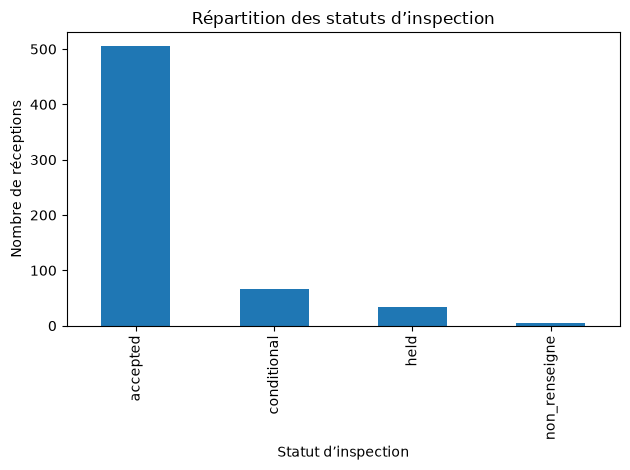

In [8]:
effectifs = receptions["inspection_status"].fillna("non_renseigne").value_counts()

display(pd.DataFrame({
    "nombre": effectifs,
    "pourcentage": (effectifs / len(receptions) * 100).round(2)
}))

effectifs.plot.bar()
plt.title("Répartition des statuts d’inspection")
plt.xlabel("Statut d’inspection")
plt.ylabel("Nombre de réceptions")
plt.tight_layout()
plt.show()

Les inspections sont majoritairement acceptées (82,79 %). Les statuts conditional représentent 10,98 % des réceptions et held 5,57 %. Quatre réceptions (0,66 %) n’ont pas de statut renseigné. Ces catégories sont conservées : un statut conditionnel ou en attente ne constitue pas une erreur de données.

In [9]:
display(
    receptions[receptions["inspection_status"].isna()][[
        "receipt_number",
        "receipt_date",
        "received_quantity",
        "received_unit",
        "receipt_status"
    ]]
)

,receipt_number,receipt_date,received_quantity,received_unit,receipt_status
76,rcv-2017-00077,2017-12-31,26.00,pallet,posted
364,rcv-2022-00365,2022-11-10,72.00,case,posted
432,rcv-2023-00433,2023-05-02,0.82,service,posted
603,rcv-2025-00604,2025-06-13,37.00,pack,posted


Les quatre statuts d’inspection manquants concernent des réceptions comptabilisées (posted), de dates et d’unités différentes. Les autres champs examinés ne permettent pas de reconstituer l’information. Nous conservons donc ces valeurs manquantes et les lignes correspondantes.

### CM1 — Statuts d’enregistrement

`receipt_status` décrit l’enregistrement et ne remplace pas le résultat de l’inspection.

In [10]:
effectifs = receptions["receipt_status"].value_counts(dropna=False)

display(pd.DataFrame({
    "nombre": effectifs,
    "pourcentage": (effectifs / len(receptions) * 100).round(2)
}))

,nombre,pourcentage
receipt_status,,
posted,576,94.43
quality_hold,34,5.57


Les réceptions sont majoritairement comptabilisées (94,43 %). Les réceptions en attente pour qualité représentent 5,57 %.

**Bilan du fichier :** aucune correction supplémentaire n’est établie par ces seules descriptions.
Les réceptions fractionnaires de services ou de contrats restent à expliquer ; elles ne sont pas supprimées.

## 3. `purchase_order_lines.csv` — Commandes

### CM1 — Prix pour un même article, une même unité et une même devise
**Question :** de quelle ampleur sont les variations de prix dans un groupe comparable ?
On ne compare pas directement les montants de devises différentes. Un écart-type absent
dans un groupe d’une observation est attendu. Les prix peuvent varier selon la date,
le fournisseur ou les conditions d’achat.

In [11]:
commandes = tables_nettoyees["purchase_order_lines"]

bilan_prix = commandes.groupby(
    ["item_code", "ordered_unit", "currency"]
)["unit_price"].describe()

display(bilan_prix.round(2))

count     mean     std      min      25%  \
item_code   ordered_unit currency                                             
itm-age-001 unit         avl         3.0  5192.85  530.18  4797.82  4891.58   
                         krn         2.0  5481.03  607.12  5051.73  5266.38   
                         ndh         1.0  5405.38     NaN  5405.38  5405.38   
                         tmb         3.0  5311.43   48.05  5282.29  5283.70   
                         vln        14.0  5614.64  368.61  5067.98  5268.70   
...                                  ...      ...     ...      ...      ...   
itm-trn-001 service      avl         3.0  4123.00  515.63  3529.88  3952.21   
                         krn         3.0  3909.48  454.91  3509.03  3662.16   
                         ndh         4.0  3769.90  358.90  3467.84  3468.19   
                         tmb         8.0  3840.08  327.47  3457.80  3566.59   
                         vln        15.0  3962.24  255.51  3482.27  3766.70   

                                       50%      75%      max  
item_code   ordered_unit currency                             
itm-age-001 unit         avl       4985.33  5390.37  5795.41  
                         krn       5481.03  5695.68  5910.33  
                         ndh       5405.38  5405.38  5405.38  
                         tmb       5285.11  5326.00  5366.89  
                         vln       5701.60  5841.08  6172.73  
...                                    ...      ...      ...  
itm-trn-001 service      avl       4374.54  4419.57  4464.59  
                         krn       3815.30  4109.70  4404.10  
                         ndh       3717.53  4019.24  4176.70  
                         tmb       3826.23  4045.33  4403.98  
                         vln       4045.45  4121.14  4412.89  

[126 rows x 8 columns]

**Exemple ciblé :** `itm-age-001`, unité `unit`, devise `vln`, comporte 14 observations.
Le boxplot illustre la dispersion de ce groupe. Cet exemple ne constitue pas un contrôle
exhaustif de tous les articles ; son choix ne démontre pas qu’il est problématique.

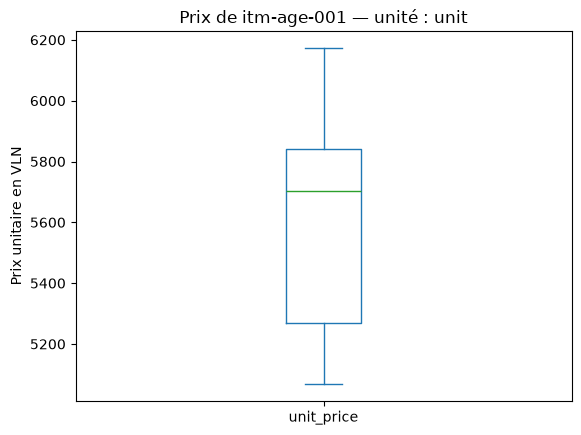

In [12]:
prix_article = commandes[
    (commandes["item_code"] == "itm-age-001")
    & (commandes["ordered_unit"] == "unit")
    & (commandes["currency"] == "vln")
]

prix_article["unit_price"].plot.box()
plt.title("Prix de itm-age-001 — unité : unit")
plt.ylabel("Prix unitaire en VLN")
plt.show()

### CM1 — État des commandes

**Question :** quels statuts sont présents ? Une commande ouverte et une commande terminée ne s’interprètent pas de la même façon.

In [13]:
effectifs = commandes["order_status"].value_counts(dropna=False)
display(pd.DataFrame({
    "nombre": effectifs,
    "pourcentage": (effectifs / len(commandes) * 100).round(2)
}))

,nombre,pourcentage
order_status,,
completed,610,93.85
delayed,18,2.77
pending,14,2.15
cancelled,8,1.23


**À poursuivre :** les prix varient, mais cette description n’établit pas de prix erroné.
Une réception partielle ou une variation temporelle doit être étudiée avant de qualifier un écart.

## 4. `inventory_adjustments.csv` — Ajustements

### CM1 — Quantités signées et statuts
**Question :** quelles sont les distributions des ajustements selon les catégories et unités ?
Les valeurs négatives sont conservées. On ne somme pas des quantités d’unités différentes.
Le statut de l’ajustement doit rester visible : `posted`, `approved` et `pending_review`
ne prouvent pas le même niveau d’enregistrement.

In [14]:
ajustements = tables_nettoyees["inventory_adjustments"].copy()
display(ajustements.groupby(["item_category", "unit"])["adjustment_quantity"].describe().round(2))
display(ajustements["adjustment_status"].value_counts(dropna=False))

,,count,mean,std,min,25%,50%,75%,max
item_category,unit,,,,,,,,
agricultural_product,pallet,19.0,-0.45,4.22,-7.91,-3.30,1.00,2.42,7.24
biological_sample,sealed_lot,36.0,-1.36,4.07,-7.25,-3.65,-2.40,1.00,7.45
medical_consumables,case,51.0,-1.55,2.72,-7.88,-2.56,-2.07,-1.39,7.41
monitoring_equipment,kit,20.0,1.45,4.72,-5.10,-3.32,1.00,6.24,7.74
protective_equipment,case,14.0,1.70,4.79,-7.29,-1.00,2.11,5.92,7.87


adjustment_status
posted            90
pending_review    25
approved          25
Name: count, dtype: int64

### CM1 — Références manquantes selon le motif
**Question :** l’absence de référence concerne-t-elle certains motifs ?
Ce tableau décrit une absence d’information ; il ne suffit pas à prouver une irrégularité.

In [15]:
ajustements = tables_nettoyees["inventory_adjustments"].copy()

ajustements["sans_reference"] = (
    ajustements["related_receipt_number"].isna()
    & ajustements["related_shipment_number"].isna()
)

display(
    ajustements.groupby("adjustment_reason")["sans_reference"]
    .agg(["count", "sum"])
    .rename(columns={"count": "nombre_total", "sum": "sans_reference"})
)

,nombre_total,sans_reference
adjustment_reason,,
controlled-area consumption,9,9
cycle count correction,23,14
cycle count reconciliation,5,0
damaged packaging write-off,16,10
late receipt posting,9,5
procedure stock issue,10,10
quality-hold release,21,10
specialist programme issue,11,11
transfer posting correction,24,10


Parmi les 140 ajustements de stock, 95 (67,86 %) ne comportent ni référence de réception ni référence d’expédition. Ces absences varient selon le motif. Certains motifs évoquent des usages internes ; d’autres nécessitent une vérification supplémentaire. Nous conservons les lignes et les valeurs manquantes afin de préserver cette information pour l’analyse

**À poursuivre :** examiner les motifs et les statuts avant de chercher si un ajustement
explique un écart mensuel. Le dictionnaire ne précise pas si les ajustements sont déjà
inclus dans les mouvements du bilan de stock.

## 5. `inventory_month_end.csv` — Stocks mensuels

### CM1 — Vue générale sur les cinq catégories
**Question :** quels niveaux de stock sont observés selon la catégorie et l’unité ?
On conserve toutes les catégories dans ce premier bilan. Les stocks finaux sont des niveaux
à des dates différentes : leur somme sur plusieurs mois n’est pas un volume transporté.

In [16]:
stocks = tables_nettoyees["inventory_month_end"]

display(stocks.groupby(
    ["item_category", "unit"]
)["closing_stock"].describe().round(2))

,,count,mean,std,min,25%,50%,75%,max
item_category,unit,,,,,,,,
agricultural_product,pallet,100.0,22.85,15.38,0.0,8.80,21.01,36.20,56.03
biological_sample,sealed_lot,100.0,13.53,18.48,0.0,0.00,3.96,23.66,67.81
medical_consumables,case,100.0,63.36,64.75,0.0,23.23,34.14,82.63,270.62
monitoring_equipment,kit,100.0,34.64,22.92,0.0,17.62,28.53,46.19,107.40
protective_equipment,case,100.0,36.72,32.22,0.0,14.07,27.02,58.42,141.61


### CM1 — Corrélations, puis graphiques par site
**Question ciblée :** les réceptions, sorties, usages, déchets et stocks évoluent-ils ensemble
pour les consommables médicaux en `case` ? Pearson et Spearman sont calculés comme dans
le CM1 (diapositives 17 et 20). On restreint la catégorie et l’unité pour éviter de mélanger
des marchandises différentes. Cette exploration ne couvre pas tout le dossier logistics.

In [17]:
stocks = tables_nettoyees["inventory_month_end"]

stocks_medicaux = stocks[
    (stocks["item_category"] == "medical_consumables")
    & (stocks["unit"] == "case")
]

variables = [
    "received_quantity",
    "outgoing_quantity",
    "documented_internal_use",
    "documented_waste",
    "closing_stock"
]

print("Pearson")
display(stocks_medicaux[variables].corr(method="pearson").round(2))

print("Spearman")
display(stocks_medicaux[variables].corr(method="spearman").round(2))

Pearson


,received_quantity,outgoing_quantity,documented_internal_use,documented_waste,closing_stock
received_quantity,1.00,-0.09,0.33,0.26,0.60
outgoing_quantity,-0.09,1.00,0.05,-0.01,-0.03
documented_internal_use,0.33,0.05,1.00,0.57,0.73
documented_waste,0.26,-0.01,0.57,1.00,0.73
closing_stock,0.60,-0.03,0.73,0.73,1.00


Spearman


,received_quantity,outgoing_quantity,documented_internal_use,documented_waste,closing_stock
received_quantity,1.00,-0.08,0.17,0.11,0.34
outgoing_quantity,-0.08,1.00,0.07,0.13,-0.09
documented_internal_use,0.17,0.07,1.00,0.48,0.63
documented_waste,0.11,0.13,0.48,1.00,0.66
closing_stock,0.34,-0.09,0.63,0.66,1.00


Les stocks finaux élevés tendent à être associés à davantage d’usage interne et de déchets. Cette association apparaît avec Pearson et Spearman. Elle peut notamment refléter des différences de taille ou d’activité entre sites. La relation entre réceptions et stock final est moins marquée avec Spearman ; sa forme et l’influence éventuelle de grandes valeurs doivent être examinées graphiquement. Ces corrélations ne démontrent pas de causalité.

Le couple stock final × usage interne est visualisé car les deux coefficients sont élevés. Les couleurs permettent d’examiner les différences entre sites.

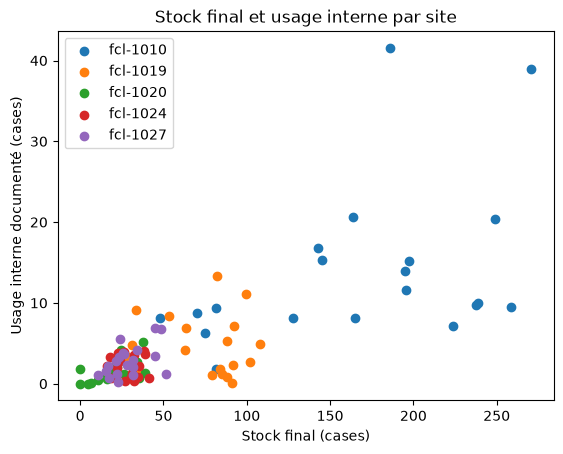

In [18]:
fig, ax = plt.subplots()

for site, groupe in stocks_medicaux.groupby("facility_code"):
    ax.scatter(
        groupe["closing_stock"],
        groupe["documented_internal_use"],
        label=site
    )

ax.set_xlabel("Stock final (cases)")
ax.set_ylabel("Usage interne documenté (cases)")
ax.set_title("Stock final et usage interne par site")
ax.legend()
plt.show()

Nous visualisons la relation entre stock final et usage interne, car elle présente des coefficients de corrélation élevés avec Pearson et Spearman. La coloration par site permet d’examiner le rôle des différences entre établissements.

La coloration par site montre que la corrélation globale reflète en partie des différences entre établissements. Le site fcl-1010 se distingue par des niveaux élevés de stock final et d’usage interne. On ne peut donc pas déduire de la corrélation globale que cette relation est identique au sein de chaque site. Ces niveaux élevés ne constituent pas, à eux seuls, des anomalies.

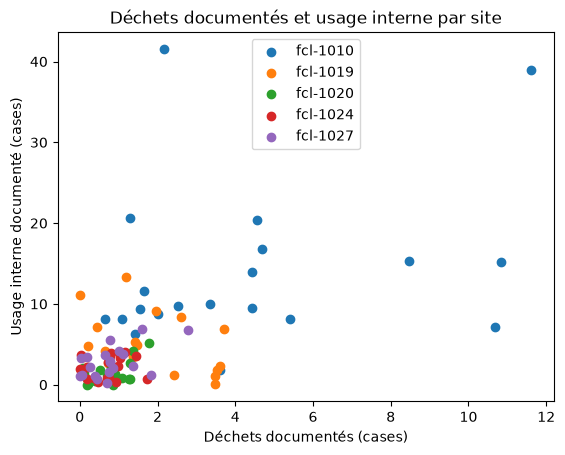

In [19]:
fig, ax = plt.subplots()

for site, groupe in stocks_medicaux.groupby("facility_code"):
    ax.scatter(
        groupe["documented_waste"],
        groupe["documented_internal_use"],
        label=site
    )

ax.set_xlabel("Déchets documentés (cases)")
ax.set_ylabel("Usage interne documenté (cases)")
ax.set_title("Déchets documentés et usage interne par site")
ax.legend()
plt.show()

Les déchets documentés et l’usage interne présentent une association positive, avec une dispersion importante. Les différences de niveaux entre sites contribuent vraisemblablement à cette association. Le graphique ne permet pas d’établir qu’un usage interne élevé provoque davantage de déchets, ni d’identifier une anomalie à lui seul.

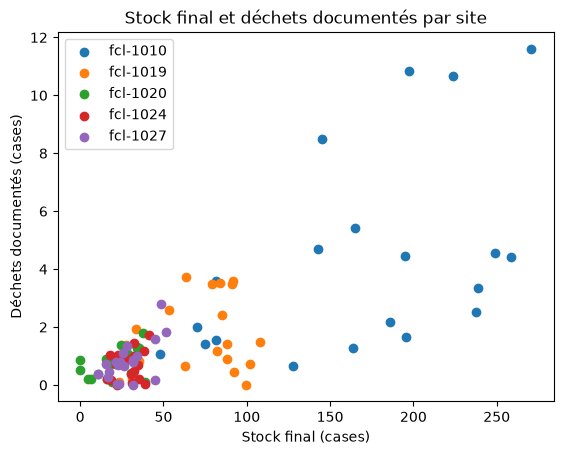

In [20]:
fig, ax = plt.subplots()

for site, groupe in stocks_medicaux.groupby("facility_code"):
    ax.scatter(
        groupe["closing_stock"],
        groupe["documented_waste"],
        label=site
    )

ax.set_xlabel("Stock final (cases)")
ax.set_ylabel("Déchets documentés (cases)")
ax.set_title("Stock final et déchets documentés par site")
ax.legend()
plt.show()

Une association positive apparaît entre stock final et déchets documentés. La coloration montre que les différences entre sites contribuent à cette relation. Les quantités de déchets seules ne permettent pas de comparer leur efficacité : un établissement plus actif peut produire davantage de déchets en volume

Les corrélations et les graphiques montrent que les stocks finaux élevés sont associés à davantage d’usage interne et de déchets. Le site fcl-1010 présente les niveaux les plus élevés sur ces variables. Ces différences peuvent refléter des volumes d’activité différents et ne suffisent pas à identifier une anomalie. Nous poursuivons donc avec une comparaison des profils des sites.

### CM2 — Profils moyens des sites
**Question :** quels sites ont des profils proches sur ces cinq variables ?
Chaque site est décrit par ses moyennes mensuelles. Cette synthèse masque les variations
entre mois et ne compare pas des trajectoires temporelles. On affiche aussi l’effectif et
les bornes de période : un même nombre de mois ne garantit pas les mêmes dates observées.

In [21]:
profils_sites = stocks_medicaux.groupby("facility_code")[variables].mean()

display(profils_sites.round(2))

,received_quantity,outgoing_quantity,documented_internal_use,documented_waste,closing_stock
facility_code,,,,,
fcl-1010,33.23,2.94,14.07,4.32,167.62
fcl-1019,9.06,1.70,4.67,1.71,71.07
fcl-1020,3.25,3.99,1.46,0.76,21.09
fcl-1024,3.86,2.02,2.16,0.68,28.41
fcl-1027,3.76,1.81,2.83,0.82,28.59


In [22]:
display(stocks_medicaux.groupby("facility_code")["reporting_month"].agg(["count", "min", "max"]))

,count,min,max
facility_code,,,
fcl-1010,20,2018-02-01,2025-06-01
fcl-1019,20,2018-02-01,2025-06-01
fcl-1020,20,2018-02-01,2025-06-01
fcl-1024,20,2018-02-01,2025-06-01
fcl-1027,20,2018-02-01,2025-06-01


- fcl-1010 présente les moyennes les plus élevées, sauf pour les sorties.
- fcl-1020 présente la moyenne des sorties la plus élevée : 3,99 cases.
- fcl-1024 et fcl-1027 ont des profils proches.

#### Standardisation
Nous donnons le même poids initial à chaque variable dans la comparaison, afin que les
valeurs numériques du stock ne dominent pas mécaniquement celles des déchets.
Les variables corrélées peuvent néanmoins renforcer une même dimension d’activité.
Le tableau original est conservé pour lire les quantités en `case`.

In [23]:
from sklearn.preprocessing import StandardScaler

profils_standardises = pd.DataFrame(
    StandardScaler().fit_transform(profils_sites),
    index=profils_sites.index,
    columns=profils_sites.columns
)

display(profils_standardises.round(2))

,received_quantity,outgoing_quantity,documented_internal_use,documented_waste,closing_stock
facility_code,,,,,
fcl-1010,1.97,0.51,1.95,1.93,1.89
fcl-1019,-0.14,-0.91,-0.08,0.03,0.14
fcl-1020,-0.64,1.73,-0.77,-0.65,-0.77
fcl-1024,-0.59,-0.55,-0.62,-0.71,-0.63
fcl-1027,-0.60,-0.78,-0.48,-0.61,-0.63


La standardisation confirme les différences observées :
- fcl-1010 est au-dessus de la moyenne sur les cinq variables, surtout les réceptions, l’usage interne, les déchets et le stock.
- fcl-1020 se distingue par ses sorties : +1,73 écart-type.
- fcl-1024 et fcl-1027 restent proches.

### Choix de la métrique — Distance euclidienne
Nous comparons les cinq profils de sites à partir des variables numériques standardisées. Nous choisissons la distance euclidienne pour mesurer leurs écarts en tenant compte de chaque variable avec le même poids initial. Il s’agit d’une mesure de dissimilarité : une petite distance indique des profils proches, une grande distance des profils éloignés. La diagonale vaut zéro, car un site est identique à lui-même. Les variables corrélées peuvent toutefois donner davantage de poids à une même dimension d’activité. Cette distance est compatible avec le regroupement de Ward utilisé ensuite.

In [24]:
from sklearn.metrics import pairwise_distances

distances = pd.DataFrame(
    pairwise_distances(profils_standardises, metric="euclidean"),
    index=profils_standardises.index,
    columns=profils_standardises.index
)

display(distances.round(2))

facility_code,fcl-1010,fcl-1019,fcl-1020,fcl-1024,fcl-1027
facility_code,,,,,
fcl-1010,0.00,4.15,5.42,5.25,5.19
fcl-1019,4.15,0.00,3.00,1.33,1.18
fcl-1020,5.42,3.00,0.00,2.29,2.53
fcl-1024,5.25,1.33,2.29,0.00,0.29
fcl-1027,5.19,1.18,2.53,0.29,0.00


#### PCA à deux axes — CM2, diapositive 14
On cherche une représentation lisible des cinq profils. Les axes sont des combinaisons
des variables standardisées, sans unité. La variance expliquée mesure la part conservée,
pas la qualité de fonctionnement des sites.

In [25]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2)

coordonnees = pd.DataFrame(
    pca.fit_transform(profils_standardises),
    index=profils_standardises.index,
    columns=["PC1", "PC2"]
)

display(coordonnees.round(2))

print(
    "Variance expliquée par axe (%) :",
    (pca.explained_variance_ratio_ * 100).round(2)
)

,PC1,PC2
facility_code,,
fcl-1010,3.89,0.21
fcl-1019,-0.09,-0.92
fcl-1020,-1.28,1.84
fcl-1024,-1.31,-0.45
fcl-1027,-1.21,-0.69


Variance expliquée par axe (%) : [80.02 19.75]


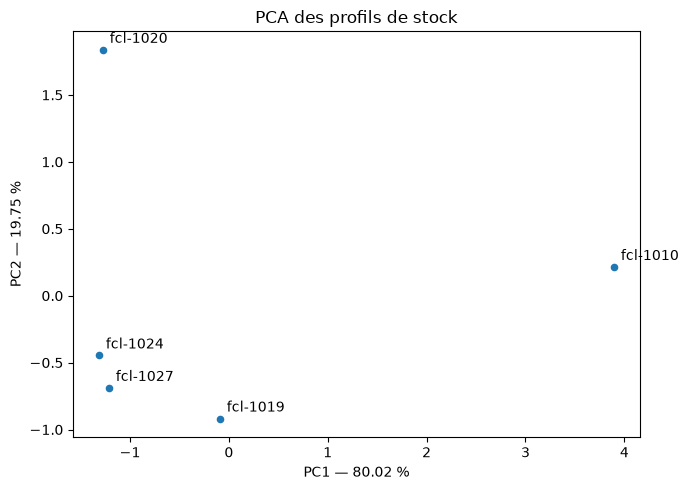

In [26]:
coordonnees.plot.scatter(x="PC1", y="PC2", figsize=(7, 5))

for site, ligne in coordonnees.iterrows():
    plt.annotate(
        site,
        (ligne["PC1"], ligne["PC2"]),
        xytext=(5, 5),
        textcoords="offset points"
    )

plt.xlabel(f"PC1 — {pca.explained_variance_ratio_[0] * 100:.2f} %")
plt.ylabel(f"PC2 — {pca.explained_variance_ratio_[1] * 100:.2f} %")
plt.title("PCA des profils de stock")
plt.tight_layout()
plt.show()

In [27]:
poids = pd.DataFrame(
    pca.components_.T,
    index=variables,
    columns=["PC1", "PC2"]
)

display(poids.round(2))

,PC1,PC2
received_quantity,0.50,0.01
outgoing_quantity,0.08,0.99
documented_internal_use,0.50,-0.07
documented_waste,0.50,-0.01
closing_stock,0.50,-0.08


La PCA distingue principalement un niveau conjoint de réceptions, d’usage interne, de déchets et de stock final, puis le niveau des sorties. Le site fcl-1010 se distingue sur la première dimension et fcl-1020 sur la seconde. Les sites fcl-1024 et fcl-1027 présentent des profils proches. Les deux axes expliquent ensemble 99,77 % de la variance des cinq profils étudiés.

#### Regroupement hiérarchique — CM2, diapositive 17
L’approche agglomérative figure dans le CM ; Ward est notre choix d’agrégation.
Cette méthode utilise la distance euclidienne et limite l’augmentation de dispersion interne.
Le dendrogramme aide à choisir une coupe ; le nombre de groupes n’est pas démontré comme optimal.
Avec cinq sites, l’analyse reste exploratoire.

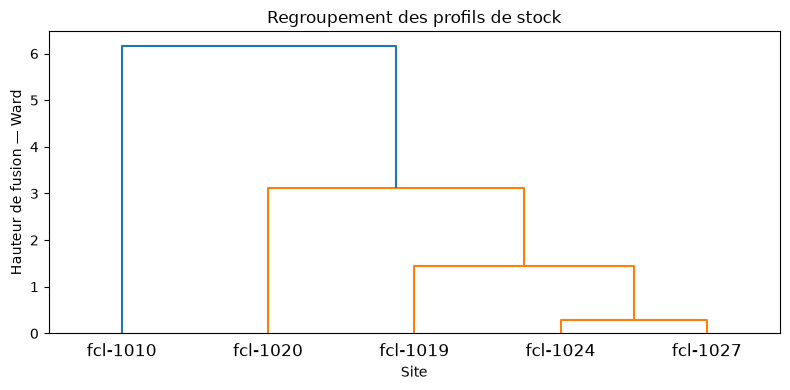

In [28]:
from scipy.cluster.hierarchy import linkage, dendrogram

liaisons = linkage(profils_standardises, method="ward", metric="euclidean")

plt.figure(figsize=(8, 4))
dendrogram(
    liaisons,
    labels=profils_standardises.index.tolist()
)

plt.title("Regroupement des profils de stock")
plt.xlabel("Site")
plt.ylabel("Hauteur de fusion — Ward")
plt.tight_layout()
plt.show()

La classification hiérarchique rapproche d’abord fcl-1024 et fcl-1027. Une coupe avant la dernière fusion distingue fcl-1010 des quatre autres sites, principalement en raison de ses niveaux élevés sur plusieurs variables de stock. Cette séparation décrit une différence de profil ; elle ne démontre pas une anomalie. Avec cinq sites, le regroupement reste exploratoire.

In [29]:
from scipy.cluster.hierarchy import fcluster

resultats = profils_sites.copy()
resultats["groupe"] = fcluster(
    liaisons, t=2, criterion="maxclust"
)

display(resultats.round(2))

,received_quantity,outgoing_quantity,documented_internal_use,documented_waste,closing_stock,groupe
facility_code,,,,,,
fcl-1010,33.23,2.94,14.07,4.32,167.62,2
fcl-1019,9.06,1.70,4.67,1.71,71.07,1
fcl-1020,3.25,3.99,1.46,0.76,21.09,1
fcl-1024,3.86,2.02,2.16,0.68,28.41,1
fcl-1027,3.76,1.81,2.83,0.82,28.59,1


### CM3 — Écarts de bilan à expliquer
**Question :** les mouvements du même bilan expliquent-ils le stock final enregistré ?
On calcule : stock initial + réceptions − sorties − usage interne − déchets.
L’écart est le stock enregistré moins le stock calculé. Une tolérance exploratoire de 0,05
écarte les petits arrondis ; ce n’est pas un seuil métier universel.

Les ajustements séparés ne sont pas intégrés ici. Les écarts restent donc **à expliquer**.
Un stock calculé négatif avec un stock final nul peut évoquer un plancher à zéro ou des
mouvements incomplets. On n’applique pas de correction ni de classement global mélangeant les unités.

In [30]:
bilan_stock = stocks.copy()
bilan_stock["stock_calcule"] = (
    bilan_stock["opening_stock"]
    + bilan_stock["received_quantity"]
    - bilan_stock["outgoing_quantity"]
    - bilan_stock["documented_internal_use"]
    - bilan_stock["documented_waste"]
)
bilan_stock["ecart"] = (bilan_stock["closing_stock"] - bilan_stock["stock_calcule"]).round(2)

display(bilan_stock.groupby(["item_category", "unit"])["ecart"].describe().round(2))
ecarts = bilan_stock[bilan_stock["ecart"].abs() > 0.05]
print("Nombre de lignes avec un écart :", len(ecarts), "sur", len(bilan_stock))
print("Aperçu des lignes concernées (sans classement de gravité) :")
display(ecarts[[
    "facility_code", "reporting_month", "item_category", "unit",
    "stock_calcule", "closing_stock", "ecart"
]].head(15))

,,count,mean,std,min,25%,50%,75%,max
item_category,unit,,,,,,,,
agricultural_product,pallet,100.0,0.83,4.16,-10.10,-0.70,0.48,1.90,34.15
biological_sample,sealed_lot,100.0,-0.92,5.20,-21.80,-2.23,0.28,2.05,8.64
medical_consumables,case,100.0,-0.33,4.46,-17.76,-1.51,-0.34,1.84,24.17
monitoring_equipment,kit,100.0,-0.29,3.31,-17.23,-1.07,0.15,1.08,7.69
protective_equipment,case,100.0,0.60,4.86,-9.75,-1.06,0.08,1.38,44.37


Nombre de lignes avec un écart : 492 sur 500
Aperçu des lignes concernées (sans classement de gravité) :


,facility_code,reporting_month,item_category,unit,stock_calcule,closing_stock,ecart
0,fcl-1024,2018-02-01,biological_sample,sealed_lot,19.30,16.24,-3.06
1,fcl-1024,2018-03-01,biological_sample,sealed_lot,18.65,0.55,-18.10
3,fcl-1024,2019-01-01,biological_sample,sealed_lot,-1.22,0.00,1.22
4,fcl-1024,2019-08-01,biological_sample,sealed_lot,-5.76,0.00,5.76
5,fcl-1024,2019-09-01,biological_sample,sealed_lot,3.48,0.00,-3.48
6,fcl-1024,2019-11-01,biological_sample,sealed_lot,-4.63,0.00,4.63
7,fcl-1024,2020-04-01,biological_sample,sealed_lot,-5.82,0.00,5.82
8,fcl-1024,2020-06-01,biological_sample,sealed_lot,-0.38,0.00,0.38
9,fcl-1024,2021-03-01,biological_sample,sealed_lot,7.53,0.00,-7.53
10,fcl-1024,2021-05-01,biological_sample,sealed_lot,-7.15,0.00,7.15


## 6. `erp_facilities.csv` — Sites

### CM1 — Catégories et capacités déclarées
**Question :** quels types de sites et capacités sont représentés ?
Les catégories et statuts sont décrits avec des fréquences, sans encodage arbitraire.
`storage_capabilities` peut contenir plusieurs capacités dans une même chaîne : ce premier
tableau compte les libellés complets, pas chaque capacité élémentaire séparément.

In [31]:
sites = tables_nettoyees["erp_facilities"]

for col in ["facility_category", "facility_status", "storage_capabilities"]:
    print(col)
    effectifs = sites[col].fillna("non_renseigne").value_counts()
    display(pd.DataFrame({
        "nombre": effectifs,
        "pourcentage": (effectifs / len(sites) * 100).round(2)
    }))

facility_category


,nombre,pourcentage
facility_category,,
warehouse,12,40.00
laboratory_delivery_point,4,13.33
field_depot,4,13.33
transfer_hub,3,10.00
office,2,6.67
clinical_delivery_point,2,6.67
port_staging,1,3.33
service_facility,1,3.33
air_cargo_terminal,1,3.33


facility_status


,nombre,pourcentage
facility_status,,
active,30,100.0


storage_capabilities


,nombre,pourcentage
storage_capabilities,,
ambient;secure_cage,9,30.00
ambient;secure_cage;2-8c;frozen,8,26.67
ambient,6,20.00
2-8c;controlled_access,6,20.00
non_renseigne,1,3.33


**À poursuivre :** une capacité non renseignée n’est pas une absence de capacité.
Les coordonnées seraient utiles à une question géographique, mais elles ne sont pas
ajoutées à la PCA des stocks sans objectif explicite. La compatibilité avec les marchandises
nécessitera un rapprochement avec les expéditions ; le nom d’un site seul ne suffit pas.

## 7. `erp_business_partners.csv` — Partenaires

### CM1 — Rôles, statuts et classes de risque déclarés
**Question :** quels profils de partenaires sont présents ?
Les classes de risque sont des attributs déclarés ; elles ne sont pas des anomalies
démontrées. Les codes servent d’identifiants et ne sont pas des variables quantitatives.

In [32]:
partenaires = tables_nettoyees["erp_business_partners"]

for col in ["partner_role", "partner_status", "risk_class"]:
    print(col)
    effectifs = partenaires[col].value_counts(dropna=False)
    display(pd.DataFrame({
        "nombre": effectifs,
        "pourcentage": (effectifs / len(partenaires) * 100).round(2)
    }))

partner_role


,nombre,pourcentage
partner_role,,
customer,32,40.00
service_partner,19,23.75
supplier,14,17.50
carrier,9,11.25
supplier_customer,6,7.50


partner_status


,nombre,pourcentage
partner_status,,
active,72,90.0
inactive,8,10.0


risk_class


,nombre,pourcentage
risk_class,,
standard,37,46.25
review,19,23.75
low,15,18.75
elevated,9,11.25


**À poursuivre :** les numéros d’enregistrement absents et les rôles particuliers restent
des informations à contextualiser. Ils ne suffisent pas à qualifier un partenaire de problématique.

## 8. Synthèse et pistes de rapprochement entre fichiers

| Résultat | Portée | Vérification restante |
|---|---|---|
| Quantités atypiques d’échantillons biologiques et de fournitures de bureau | Règle interquartile appliquée par catégorie et unité | Comprendre les opérations concernées |
| Quatre inspections non renseignées sur des réceptions `posted` | Information manquante conservée | Ne pas déduire l’acceptation de l’inspection |
| Profil de fcl-1010 distinct sur les stocks médicaux | Moyennes de cinq variables, cinq sites | Distinguer volume d’activité et fonctionnement inhabituel |
| Écarts entre stocks calculés et enregistrés | Bilan avant prise en compte d’ajustements séparés | Vérifier conventions, statuts et éventuels doubles comptes |

**Les analyses sont exploratoires.** Les descriptions des sept fichiers ne constituent pas
un contrôle exhaustif de toutes les colonnes. Une même quantité ou un même prix peut avoir
des explications normales selon le contexte. Les conclusions fortes nécessitent des indices convergents.

### Croisement facultatif déjà exploré — Commandes et réceptions
Ce contrôle est conservé ici une seule fois. `merge()` est une jointure pandas pour préparer
et rapprocher les données, pas un nouvel algorithme statistique enseigné dans le CM.
Il vérifie l’existence de la ligne de commande et la concordance des unités ; il ne compare
pas encore les quantités totales reçues aux quantités commandées.

In [33]:
commandes = tables_nettoyees["purchase_order_lines"]
receptions = tables_nettoyees["goods_receipts"]

cles = ["purchase_order_number", "purchase_order_line"]

comparaison = receptions.merge(
    commandes[cles + ["ordered_quantity", "ordered_unit"]],
    on=cles,
    how="left",
    validate="many_to_one",
    indicator=True
)

print(
    "Réceptions sans commande :",
    comparaison["_merge"].eq("left_only").sum()
)

unites_differentes = comparaison[
    comparaison["_merge"].eq("both")
    & comparaison["received_unit"].ne(comparaison["ordered_unit"])
]

print("Réceptions avec une unité différente :", len(unites_differentes))

display(unites_differentes[
    cles + ["received_quantity", "received_unit",
            "ordered_quantity", "ordered_unit"]
])

Réceptions sans commande : 0
Réceptions avec une unité différente : 0


,purchase_order_number,purchase_order_line,received_quantity,received_unit,ordered_quantity,ordered_unit


**Suite de l’enquête, à travailler étape par étape :**

- Examiner les écarts de stock par site, catégorie, unité et mois.
- Établir si les ajustements `posted` sont déjà inclus dans les mouvements avant de les ajouter.
- Vérifier les réceptions partielles et les statuts avant de comparer les quantités aux commandes.
- Rapprocher les marchandises et conditions déclarées des capacités des sites.

Ces pistes ne sont pas des conclusions sur le récit caché. Chaque nouveau calcul devra être
précédé de sa question et de la justification de sa méthode.